In [14]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from datetime import datetime
import os
import seaborn as sns
import harmonypy as hm
import squidpy as sq
import sympy

from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# For cleaner output
import warnings
warnings.filterwarnings('ignore')

In [2]:
base_dir = "/scratch/svc_td_regene/eye_retinopathy/scs_data/"
os.chdir('/scratch/svc_td_regene/eye_retinopathy')

date = datetime.today().strftime('%Y%m%d')
date

'20261119'

In [3]:
# load data
spatial_data = sc.read_h5ad('./c2l_dir/cell2location_map/sp.h5ad')


In [6]:
# Rename early and late fibrosis clusters to a single fibrosis cluster
cluster_renaming_dict = {
    '0': 'Inflammation',
    '1': 'Angiogenesis',
    '2': 'Fibrosis',
    '3': 'Fibrosis',
    '4': 'Fibrosis'
}

spatial_data.obs['cluster'] = spatial_data.obs['leiden'].map(cluster_renaming_dict)
spatial_data.obs['cluster'] = pd.Categorical(spatial_data.obs['cluster'], categories=['Inflammation', 'Angiogenesis', 'Fibrosis'])

samples = ['human_eye_1_rerun', 'human_eye_2']
spatial_data

AnnData object with n_obs × n_vars = 1464 × 11927
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_counts', 'n_genes', 'leiden', 'cluster', '_indices', '_scvi_batch', '_scvi_labels'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'mod', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'means_cell_abundance_w_sf', 'q05_cell_abundance_w_sf', 'q95_cell_abundance_w_sf', 'spatial', 'stds_cell_abundance_w_sf'
    varm: 'PCs'
    layers: 'log1p'
    obsp: 'connectivities', 'distances'

In [15]:
spatial_data.obs[spatial_data.uns['mod']['factor_names']] = spatial_data.obsm['q05_cell_abundance_w_sf']
celltypes = [c for c in spatial_data.obs.columns if 'cell' in c]
print(celltypes)
celltypes = spatial_data.obs[celltypes].mean().sort_values(ascending=False).index.to_list()
print(celltypes)

['B cell', 'Endothelial cell_0', 'Endothelial cell_1', 'Endothelial cell_2', 'Endothelial cell_3', 'Endothelial cell_4', 'Myeloid cell_0', 'Myeloid cell_1', 'Myeloid cell_2', 'Myeloid cell_3', 'Myeloid cell_4', 'Myeloid cell_5', 'Myeloid cell_6', 'Plasma cell', 'Stromal cell_0', 'Stromal cell_1', 'Stromal cell_2', 'Stromal cell_3', 'Stromal cell_4', 'T cell_0', 'T cell_1', 'T cell_2', 'T cell_3']
['Stromal cell_0', 'Stromal cell_1', 'Endothelial cell_1', 'Myeloid cell_5', 'Endothelial cell_2', 'Myeloid cell_6', 'Stromal cell_3', 'T cell_0', 'Endothelial cell_4', 'T cell_1', 'Myeloid cell_1', 'Stromal cell_4', 'Myeloid cell_0', 'Stromal cell_2', 'T cell_3', 'Endothelial cell_3', 'Myeloid cell_2', 'B cell', 'Endothelial cell_0', 'T cell_2', 'Myeloid cell_4', 'Myeloid cell_3', 'Plasma cell']


In [8]:
def load_slide(sample, obs_data, path="/scratch/svc_td_regene/eye_retinopathy/spatial_data/"):
    slide = sc.read_visium(f'{path}{sample}')
    slide.obs_names = sample + '_' + slide.obs_names
    obs_data = pd.merge(slide.obs, obs_data[obs_data['sample'] == sample], left_index=True, right_index=True, how='right')
    slide = slide[obs_data.index].copy()
    slide.obs = obs_data.copy()
    return slide

### Figure 3A

['Stromal cell_1', 'Endothelial cell_1', 'Myeloid cell_0', 'Myeloid cell_2']


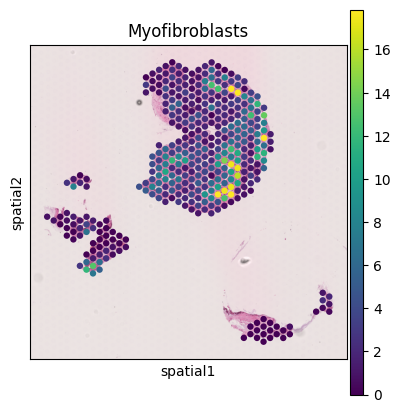

human_eye_1_rerun_spatial_mapping_Myofibroblasts


<Figure size 640x480 with 0 Axes>

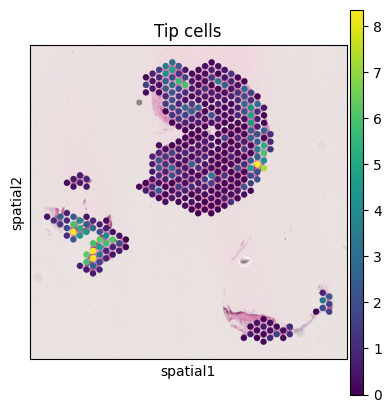

human_eye_1_rerun_spatial_mapping_Tip cells


<Figure size 640x480 with 0 Axes>

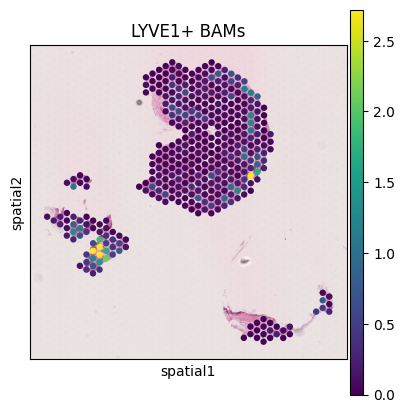

human_eye_1_rerun_spatial_mapping_LYVE1+ BAMs


<Figure size 640x480 with 0 Axes>

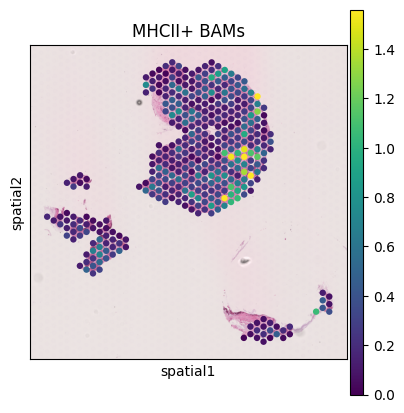

human_eye_1_rerun_spatial_mapping_MHCII+ BAMs


<Figure size 640x480 with 0 Axes>

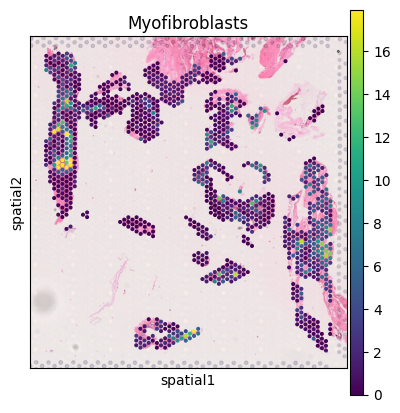

human_eye_2_spatial_mapping_Myofibroblasts


<Figure size 640x480 with 0 Axes>

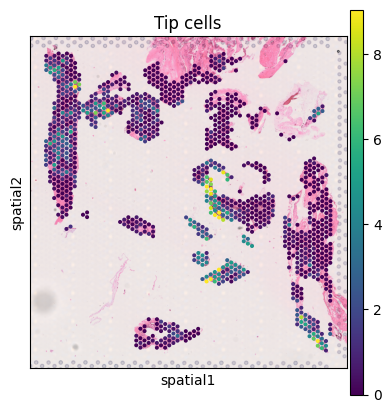

human_eye_2_spatial_mapping_Tip cells


<Figure size 640x480 with 0 Axes>

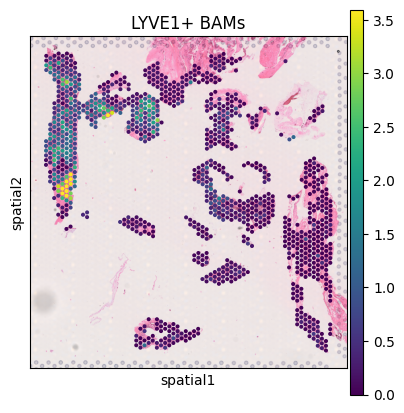

human_eye_2_spatial_mapping_LYVE1+ BAMs


<Figure size 640x480 with 0 Axes>

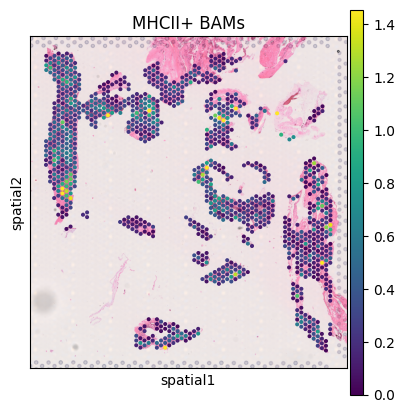

human_eye_2_spatial_mapping_MHCII+ BAMs


<Figure size 640x480 with 0 Axes>

In [16]:
%matplotlib inline
#mpl.use("Agg")

subcell_to_title = {
    'Myeloid cell_0': 'LYVE1+ BAMs',
    'Myeloid cell_2': 'MHCII+ BAMs',
    #'Myeloid cell_3': 'Monocytes',
    #'Myeloid cell_4': 'Dendritic cells',
    #'Myeloid cell_6': 'SAMs',
    #'Stromal cell_0': 'Pericytes', 
    'Stromal cell_1': 'Myofibroblasts',
    'Endothelial cell_1': 'Tip cells'
}

desired_celltypes = [c for c in celltypes if c in subcell_to_title]
print(desired_celltypes)

for sample in samples:

    slide = load_slide(sample, spatial_data.obs)

    for celltype in desired_celltypes:

        subcell_name = subcell_to_title[celltype]
        fname = f".../{sample}_spatial_mapping_{subcell_name}_{date}.png"
        suffix = f"{sample}_spatial_mapping_{subcell_name}"

        with mpl.rc_context({ 'axes.facecolor': 'black',
                            'figure.figsize': [4.5, 5]}):
                sc.pl.spatial(
                slide, cmap='viridis',
                color=celltype,
                ncols=4,
                size=1.3,
                img_key='hires',
                vmin=0, vmax='p99.2',
                title=subcell_to_title[celltype],
                return_fig=True
            )
        print(suffix)
        plt.tight_layout()
        #plt.savefig(fname, dpi=300, bbox_inches="tight")
        plt.show()

### Figure 5A

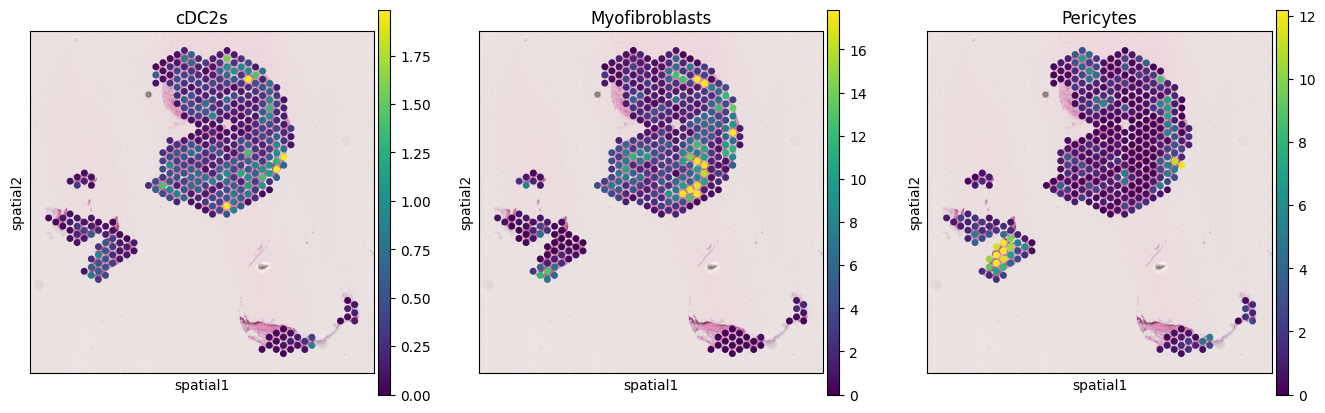

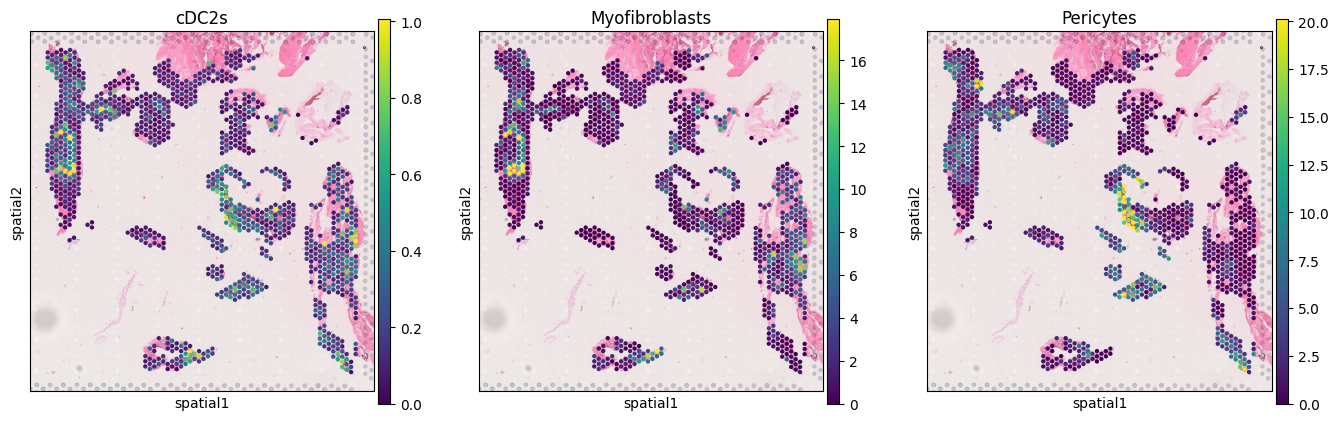

In [17]:
#mpl.use("Agg")
%matplotlib inline

# Single spatial celltype slide
for sample in samples:

    slide = load_slide(sample, spatial_data.obs)

    with mpl.rc_context({ 'axes.facecolor': 'black',
                          'figure.figsize': [4.5, 5]}):
        sc.pl.spatial(
            slide, cmap='viridis',
            color=['Myeloid cell_4', 'Stromal cell_1', 'Stromal cell_0'],
            size=1.3,
            ncols=3,
            img_key='hires',
            vmin=0, vmax='p99.2',
            title=["cDC2s", "Myofibroblasts", "Pericytes"]
        )

    #plt.tight_layout()
    #plt.savefig(f".../{sample}_cdc2_myof_peric_spatial_{date}.pdf",bbox_inches="tight", dpi=300)
    #plt.savefig(f".../{sample}_cdc2_myof_peric_spatial_{date}.png",bbox_inches="tight", dpi=300)
    plt.show()

### Supplementary figure S1A

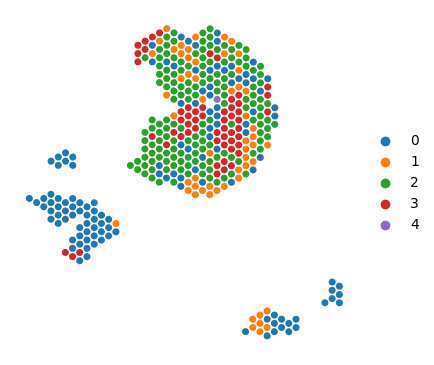

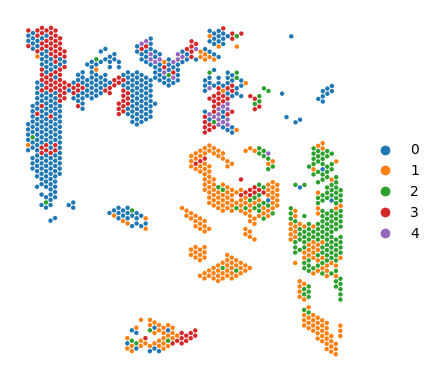

In [18]:
for sample in samples:

    slide = load_slide(sample, spatial_data.obs)

    with mpl.rc_context({ 'axes.facecolor': 'white',
                          'figure.figsize': [4.5, 5]}):
        sc.pl.spatial(
            slide, cmap='viridis',
            color='leiden',
            size=1.3,
            img_key='hires',
            vmin=0, vmax='p99.2',
            alpha=1,
            alpha_img=0,
            title="",
            frameon=False
        )

    #plt.tight_layout()
    #plt.savefig(f".../{sample}_{date}.pdf",bbox_inches="tight", dpi=300)
    #plt.savefig(f".../{sample}_{date}.png",bbox_inches="tight", dpi=300)
    plt.show()

In [12]:
# Additional look at single cell
scs_adata = sc.read_h5ad('./scs_data_clustered_annotated_250611_cellular_subtypes_for_cell2location.h5ad')

In [31]:
subcell_to_title = {
    'Endothelial cell_0': "Unidentified EC",
    'Endothelial cell_1': "Tip cells",
    'Endothelial cell_2': "VenECs", # or "Venous endothelial cells"
    'Endothelial cell_3': "Immature ECs",
    'Endothelial cell_4': "Stalk cells",
    'Stromal cell_0': "Pericytes",
    'Stromal cell_1': 'Myofibroblasts',
    'Stromal cell_2': 'Unidentified stromal cluster',
    'Stromal cell_3': 'EndMT cells',
    'Stromal cell_4': 'Müller glia cells',
    'Myeloid cell_0': 'LYVE1+ BAMs', # LYVE1+ perivascular macrophages
    'Myeloid cell_1': 'Unidentified myeloid cluster 1',
    'Myeloid cell_2': 'MHCII+ BAMs', # MHCII+ perivascular macrophages
    'Myeloid cell_3': 'Monocytes',
    'Myeloid cell_4': 'cDC2',
    'Myeloid cell_5': 'Unidentified myeloid cluster 5',
    'Myeloid cell_6': 'SAMs',
    'T cell_0': 'Exhausted CD8+ T cells',
    'T cell_1': 'CD4+ T cells',
    'T cell_2': 'γδ T cells',
    'T cell_3': 'Unidentified T cell cluster',
    'B cell': 'B cells',
    'Plasma cell': 'Plasma cells'
}

In [14]:
# Convenience function for printing dotplots
def print_dotplot(
    adata,
    genes_of_interest,
    subcell_name_map=subcell_to_title,
    subcells=None,
    save=False,
    fname="",
    log1p=False
):
    %matplotlib inline
    if save:
        mpl.use("Agg")
    adata = adata[adata.obs['celltype_leiden'].isin(subcells)].copy()
    adata.obs['leiden_common_name'] = adata.obs['celltype_leiden'].map(subcell_to_title)
    if log1p:
        sc.pl.dotplot(adata, groupby='leiden_common_name', var_names=genes_of_interest, layer='log1p')
    else:
        sc.pl.dotplot(adata, groupby='leiden_common_name', var_names=genes_of_interest)

    """if save:
        plt.savefig(f".../{fname}_{date}.pdf",bbox_inches="tight", dpi=300)
        plt.savefig(f".../{fname}_{date}.png",bbox_inches="tight", dpi=300)"""

### Figure 3D

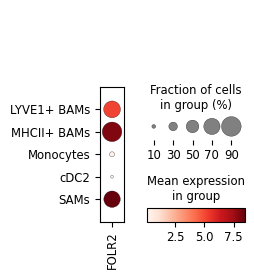

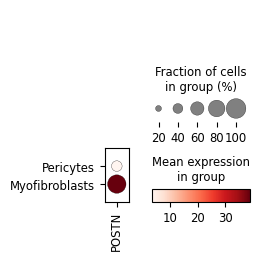

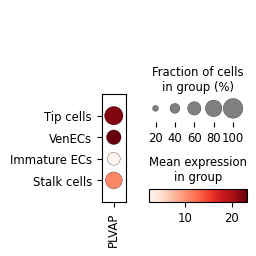

In [17]:
print_dotplot(
    adata=scs_adata,
    genes_of_interest=["FOLR2"],
    subcells=[
        'Myeloid cell_0',
        'Myeloid cell_2',
        'Myeloid cell_3',
        'Myeloid cell_4',
        'Myeloid cell_6'
    ],
    save=False,
    fname="FVM_dotplot_FOLR_in_MC"
)

print_dotplot(
    adata=scs_adata,
    genes_of_interest=["POSTN"],
    subcells=[
        'Stromal cell_0',
        'Stromal cell_1'
    ],
    save=False,
    fname="FVM_dotplot_POSTN_in_SC"
)

print_dotplot(
    adata=scs_adata,
    genes_of_interest=["PLVAP"],
    subcells=[
        'Endothelial cell_1',
        'Endothelial cell_2',
        'Endothelial cell_3',
        'Endothelial cell_4'
    ],
    save=False,
    fname="FVM_dotplot_PLVAP_in_EC"
)

### Figure 2D

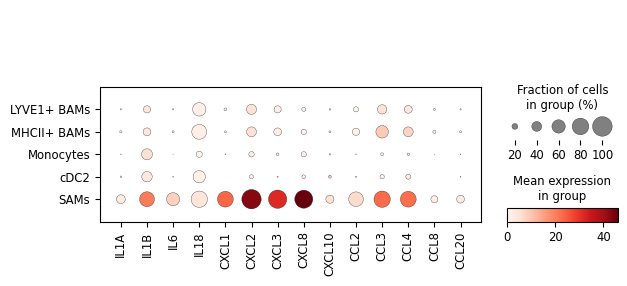

In [18]:
print_dotplot(
    adata=scs_adata,
    genes_of_interest=[
    'IL1A', 'IL1B', 'IL6', 'IL18',
    'CXCL1', 'CXCL2', 'CXCL3', 'CXCL8',
    'CXCL10', 'CCL2', 'CCL3', 'CCL4', 
    'CCL8', 'CCL20'],
    subcells=[
        'Myeloid cell_0',
        'Myeloid cell_2',
        'Myeloid cell_3',
        'Myeloid cell_4',
        'Myeloid cell_6',
    ],
    save=False,
    fname="FVM_dotplot_cytokines_in_myeloid_cells", 
    log1p=False
)

### Figure 5C

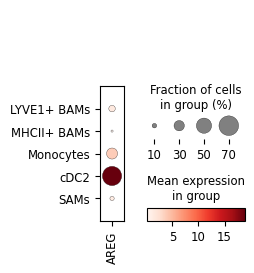

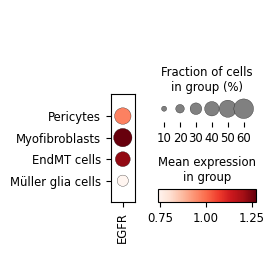

In [27]:
print_dotplot(
    adata=scs_adata,
    genes_of_interest=["AREG"],
    subcells=[
        'Myeloid cell_0',
        'Myeloid cell_2',
        'Myeloid cell_3',
        'Myeloid cell_4',
        'Myeloid cell_6'
    ],
    save=False,
    fname="FVM_dotplot_AREG_in_MC"
)

print_dotplot(
    adata=scs_adata,
    genes_of_interest=["EGFR"],
    subcells=[
        'Stromal cell_0',
        'Stromal cell_1',
        'Stromal cell_3',
        'Stromal cell_4',
    ],
    save=False,
    fname="FVM_dotplot_EGFR_in_SC"
)

### Supplementary figure S6B

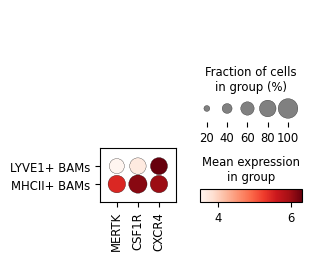

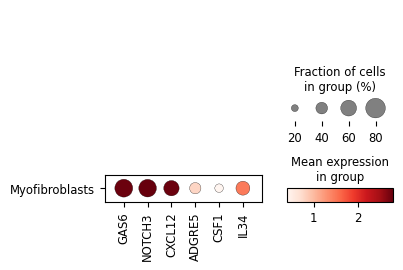

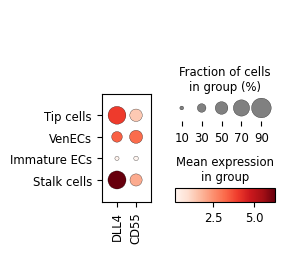

In [26]:
print_dotplot(
    adata=scs_adata,
    genes_of_interest=["MERTK", "CSF1R", "CXCR4"],
    subcells=[
        'Myeloid cell_0',
        'Myeloid cell_2'
    ],
    save=False,
    fname="FVM_dotplot_MERTK_CSFR1_CXCR4_in_BAMs"
)

print_dotplot(
    adata=scs_adata,
    genes_of_interest=["GAS6", "NOTCH3", "CXCL12", "ADGRE5", "CSF1", "IL34"],
    subcells=[
        'Stromal cell_1'
    ],
    save=False,
    fname="FVM_dotplot_macrophage_ligands_in_myofibroblast"
)

print_dotplot(
    adata=scs_adata,
    genes_of_interest=["DLL4", "CD55"],
    subcells=[
        'Endothelial cell_1',
        'Endothelial cell_2',
        'Endothelial cell_3',
        'Endothelial cell_4'
    ],
    save=False,
    fname="FVM_dotplot_DLL4_CD55_in_EC"
)

### Figure 2C

/tmp/ipykernel_2611851/1707574508.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ax = obs.groupby(["leiden_common_name", "Diabetes"]).size().unstack().plot(kind='bar', stacked=False, xlabel="", ylabel="Cell count")


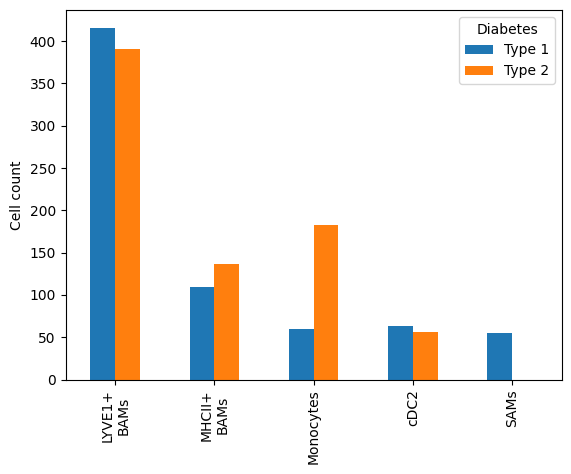

In [20]:
myeloids = ['Myeloid cell_0', 'Myeloid cell_2', 'Myeloid cell_3',
'Myeloid cell_4', 'Myeloid cell_6']

myeloid_adata = scs_adata[scs_adata.obs['celltype_leiden'].isin(myeloids)].copy()
myeloid_adata.obs['leiden_common_name'] = myeloid_adata.obs['celltype_leiden'].map(subcell_to_title)

#mpl.use("Agg")
%matplotlib inline

obs = myeloid_adata.obs
ax = obs.groupby(["leiden_common_name", "Diabetes"]).size().unstack().plot(kind='bar', stacked=False, xlabel="", ylabel="Cell count")
ax.set_xticklabels([label.get_text().replace(" ", "\n") for label in ax.get_xticklabels()])
plt.show()
#ax.figure.savefig(f".../diabetes_type_in_myeloid_subcells_unstacked_bar_chart_{date}.pdf", bbox_inches="tight", dpi=300)
#ax.figure.savefig(f".../diabetes_type_in_myeloid_subcells_unstacked_bar_chart_{date}.png", bbox_inches="tight", dpi=300)

### Figure 2B

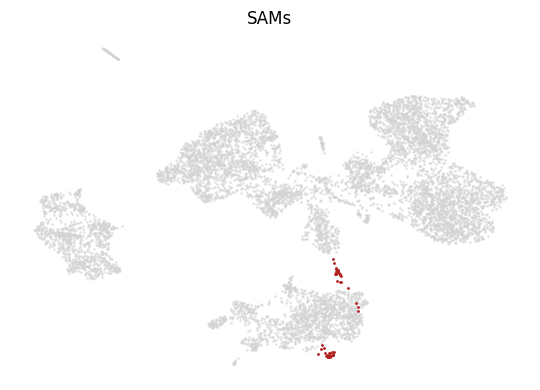

In [29]:
# Single firebrick higlight plot

umap = scs_adata.obsm['X_umap']
clusters = scs_adata.obs['celltype_leiden'].cat.categories

desired_celltype = {
    'Myeloid cell_6': 'SAMs'
}
cluster = list(desired_celltype.keys())[0]
cluster_name = desired_celltype[cluster]

fig, ax = plt.subplots(1, 1, figsize=(5.5, 4))

highlight = scs_adata.obs['celltype_leiden'] == cluster

# Other cells in lightgray
ax.scatter(umap[:, 0], umap[:, 1], s=1, color='lightgray', alpha=0.5)
# Highlight in red
ax.scatter(umap[highlight, 0], umap[highlight, 1], s=1, color='firebrick')

ax.set_title(f'{cluster_name}', fontsize=12)
ax.set_xticks([])
ax.set_yticks([])
ax.set_frame_on(False)

plt.tight_layout()
#plt.savefig(f'.../{cluster_name}_umap_highlight_{date}.pdf')
#plt.savefig(f'.../{cluster_name}_umap_highlight_{date}.png')
plt.show()

### Supplementary tables 4 and 5

In [ ]:
# With wilcoxon
# One cluster vs all rest

output_path = f"./scs_cluster_markers_vs_baseline_of_all_other_wilcoxon_{date}.xlsx"
writer = pd.ExcelWriter(output_path, engine='openpyxl')

marker_genes_dict = {}
category_results = []
# First round: global DEGs
sc.tl.rank_genes_groups(
    scs_adata,
    groupby='celltype_leiden',
    reference='rest',
    layer='log1p',
    use_raw=False,
    method='wilcoxon'
)

for g in celltypes:
    deg_results_df = sc.get.rank_genes_groups_df(scs_adata, group=g, log2fc_min=1, pval_cutoff=0.05)
    deg_results_df['annotation'] = g  # mark which group this came from
    category_results.append(deg_results_df)

combined_df = pd.concat(category_results, ignore_index=True)
combined_df.to_excel(writer, sheet_name='DEGs', index=False)  # Excel sheet names max 31 chars

# Save workbook
writer.close()

print(f"Saved differential expression results to: {output_path}")

In [ ]:
output_path = f"./scs_cluster_markers_wilcoxon_{date}.xlsx"
writer = pd.ExcelWriter(output_path, engine='openpyxl')

marker_genes_dict = {}

# First round: global DEGs
sc.tl.rank_genes_groups(
    scs_adata,
    groupby='celltype_leiden',
    reference='rest',
    layer='log1p',
    use_raw=False,
    method='wilcoxon'
)

for g in celltypes:
    deg_results_df = sc.get.rank_genes_groups_df(scs_adata, group=g, log2fc_min=1, pval_cutoff=0.05)
    top_genes_str = '(' + ', '.join(deg_results_df['names'].tolist()[:3]) + ',\n'
    marker_genes_dict[g] = top_genes_str

# Second pass: within-category DEGs
top_level_categories = scs_adata.obs['cell_type'].cat.categories.tolist()

for top_category in top_level_categories:
    celltype_groups = [c for c in celltypes if top_category in c]

    adata = scs_adata[scs_adata.obs['celltype_leiden'].isin(celltype_groups)]
    sc.tl.rank_genes_groups(
        adata,
        groupby='celltype_leiden',
        groups=celltype_groups,
        reference='rest',
        layer='log1p',
        use_raw=False,
        method='wilcoxon'
    )

    category_results = []

    for g in celltype_groups:
        deg_results_df = sc.get.rank_genes_groups_df(adata, group=g, log2fc_min=1, pval_cutoff=0.05)
        deg_results_df['annotation'] = g  # mark which group this came from
        category_results.append(deg_results_df)

        # Update marker gene string
        marker_genes_dict[g] = marker_genes_dict[g] + ', '.join(deg_results_df['names'].tolist()[:3]) + ')'

    # Concatenate and save to Excel tab for this top_category
    if category_results:
        combined_df = pd.concat(category_results, ignore_index=True)
        combined_df.to_excel(writer, sheet_name=top_category[:31], index=False)  # Excel sheet names max 31 chars

# Save workbook
writer.close()

print(f"Saved differential expression results to: {output_path}")

### NMF based colocation analysis via cell2location

In [ ]:
from cell2location import run_colocation

run_name = f'c2l_dir_mp/rerun_cell2location_map'
res_dict, spatial_data = run_colocation(
    spatial_data,
    model_name='CoLocatedGroupsSklearnNMF',
    train_args={
        'n_fact': np.arange(2, 10),
        'sample_name_col': 'sample',
        'n_restarts': 3
    },
    model_kwargs={
        'alpha': 0.01,
        'init': 'random',
        'nmf_kwd_args': {'tol': 0.000001}
    },
    export_args={'path': f'{run_name}/CoLocatedComb/'}
)

In [19]:
# Load the desired model from the output directory if the model wasn't caught in a variable in the active session
import pickle as pckl
fact3_model = pckl.load(open("/scratch/svc_td_regene/eye_retinopathy/c2l_dir_mp/rerun_cell2location_map/CoLocatedComb/CoLocatedGroupsSklearnNMF_1464locations_23factors/models/model_n_fact3.p", "rb"))

In [20]:
model = fact3_model["mod"]
model.compute_expected()
model.sample2df()

In [21]:
location_to_NMF_factors = model.location_factors_df
joined_location_df = spatial_data.obs.join(location_to_NMF_factors)

In [22]:
# The factors might need reshuffling between runs, but they remain the same content-wise
joined_location_df.rename(columns={
    'mean_nUMI_factorsfact_0': 'mean estimated NMF UMI count per spot for factor 2',
    'mean_nUMI_factorsfact_1': 'mean estimated NMF UMI count per spot for factor 0',
    'mean_nUMI_factorsfact_2': 'mean estimated NMF UMI count per spot for factor 1'
}, inplace=True)

In [23]:
def visualize_NMF_loc_factors(
    location_df_w_meta_info,
    factor_str="0",
    save=False,
    fname=""
):
    %matplotlib inline

    if save:
        mpl.use("Agg")

    column = "mean estimated NMF UMI count per spot for factor 0"
    if factor_str != "0":
        column = column.replace("0", factor_str)
    df = location_df_w_meta_info[["cluster", column]]

    sns.violinplot(df, x="cluster", y=column, hue="cluster", cut=0, inner=None, order=["Inflammation", "Angiogenesis", "Fibrosis"])
    sns.stripplot(df, x="cluster", y=column, color="black", size=2.5)

    plt.xlabel("")

    plt.tight_layout()
    

    """if save:
        plt.savefig(f".../{fname}_{date}.pdf",bbox_inches="tight", dpi=300)
        plt.savefig(f".../{fname}_{date}.png",bbox_inches="tight", dpi=300)"""
    plt.show()


### Figure 4B left side

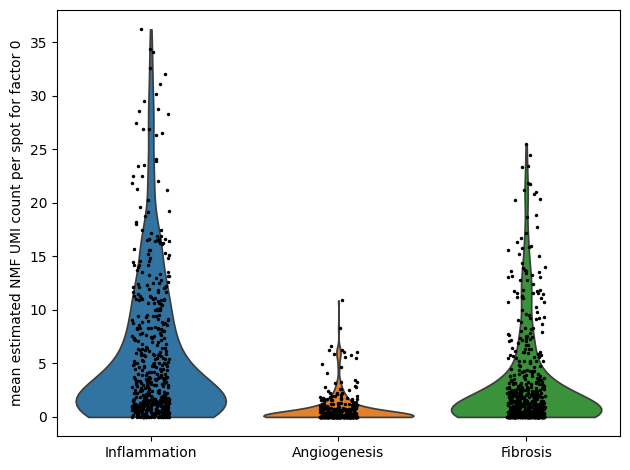

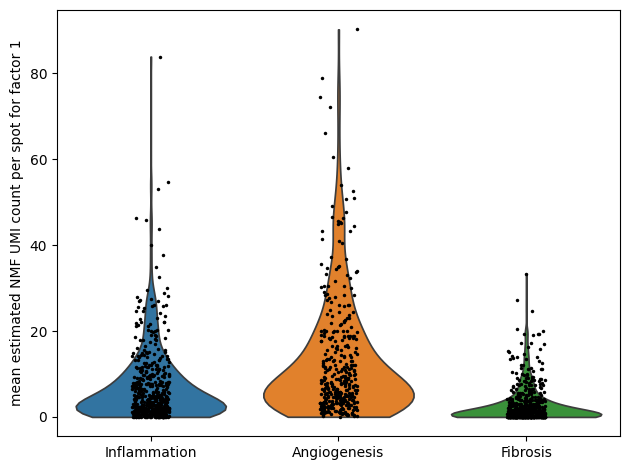

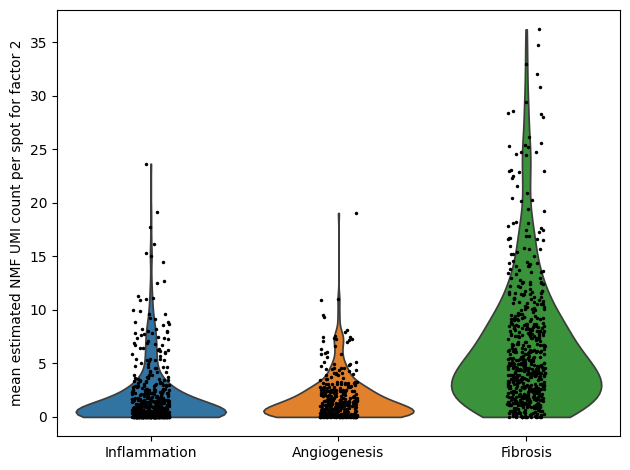

In [36]:
visualize_NMF_loc_factors(
    joined_location_df,
    factor_str="0",
    save=False,
    fname="NMF_3_location_factor_0_violin_plot"
)

visualize_NMF_loc_factors(
    joined_location_df,
    factor_str="1",
    save=False,
    fname="NMF_3_location_factor_1_violin_plot"
)

visualize_NMF_loc_factors(
    joined_location_df,
    factor_str="2",
    save=False,
    fname="NMF_3_location_factor_2_violin_plot"
)

In [24]:
model.cell_type_fractions.rename(columns={
    'mean_cell_type_factorsfact_0': 'factor 2',
    'mean_cell_type_factorsfact_1': 'factor 0',
    'mean_cell_type_factorsfact_2': 'factor 1'
}, inplace=True)

model.cell_type_fractions = model.cell_type_fractions[['factor 2',
'factor 1', 'factor 0']]

### Figure 4A 

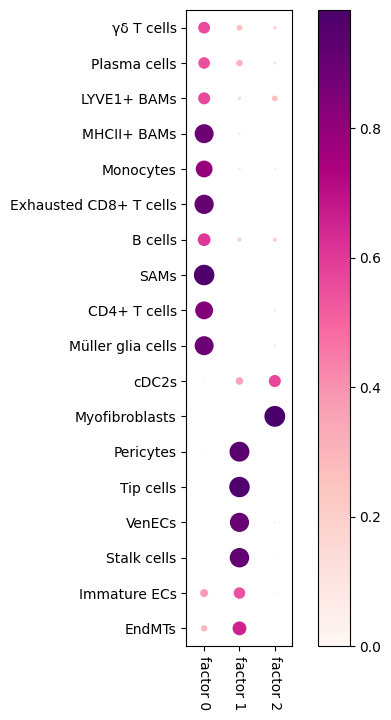

In [38]:
%matplotlib inline
#mpl.use("Agg")

NMF_cell_types = [
    "T cell_0",
    "T cell_1",
    "T cell_2",
    "Myeloid cell_2",
    "B cell",
    "Myeloid cell_6",
    "Myeloid cell_0",
    "Myeloid cell_3",
    "Plasma cell",
    "Stromal cell_4",
    "Myeloid cell_4",
    "Stromal cell_1",
    "Stromal cell_0",
    "Endothelial cell_2",
    "Endothelial cell_4",
    "Endothelial cell_1",
    "Endothelial cell_3",
    "Stromal cell_3"
]

celltype_annots = {
    "T cell_0": "Exhausted CD8+ T cells",
    "T cell_1": "CD4+ T cells",
    "T cell_2": "γδ T cells",
    "Myeloid cell_2": "LYVE1+ BAMs",
    "B cell": "B cells",
    "Myeloid cell_6": "SAMs",
    "Myeloid cell_0": "MHCII+ BAMs",
    "Myeloid cell_3": "Monocytes",
    "Plasma cell": "Plasma cells",
    "Stromal cell_4": "Müller glia cells",
    "Myeloid cell_4": "cDC2s",
    "Stromal cell_1": "Myofibroblasts",
    "Stromal cell_0": "Pericytes",
    "Endothelial cell_2": "VenECs",
    "Endothelial cell_4": "Stalk cells",
    "Endothelial cell_1": "Tip cells",
    "Endothelial cell_3": "Immature ECs",
    "Stromal cell_3": "EndMTs"
}

NMF_cell_types_annot = [
    "Exhausted CD8+ T cells",
    "CD4+ T cells",
    "γδ T cells",
    "LYVE1+ BAMs",
    "B cells",
    "SAMs",
    "MHCII+ BAMs",
    "Monocytes",
    "Plasma cells",
    "Müller glia cells",
    "cDC2s",
    "Myofibroblasts",
    "Pericytes",
    "VenECs",
    "Stalk cells",
    "Tip cells",
    "Immature ECs",
    "EndMTs"
]

model.var_names_read = model.var_names_read.map(
    lambda name: celltype_annots.get(name, name)
)


model.plot_cell_type_loadings(selected_cell_types=NMF_cell_types_annot)
#model.plot_cell_type_loadings()

plt.tight_layout()
#plt.savefig(f'.../Annotated_celltypes_in_NMF_3_factors_{date}.pdf', bbox_inches="tight", dpi=300)
#plt.savefig(f'.../Annotated_celltypes_in_NMF_3_factors_{date}.png', bbox_inches="tight", dpi=300)
plt.show()


### Figure 4B right side

In [25]:
# Direct access
loc_factors = model.samples['post_sample_means']['location_factors']
# UMI-weighted factors
nUMI_factors = model.samples['post_sample_means']['nUMI_factors']

print(loc_factors.shape)

# Recommended way: export to df and to adata
model.sample2df(node_name='nUMI_factors', ct_node_name='cell_type_factors')

# Add as cols to observations
spatial_data_c2l_annot = model.annotate_adata(spatial_data)

# what column names were added? (sample2df uses: "mean_" + node_name + fact_name)
print(model.location_factors_df.columns.tolist())
print(spatial_data_c2l_annot.obs.columns[-model.n_fact:])

(1464, 3)
['mean_nUMI_factorsfact_0', 'mean_nUMI_factorsfact_1', 'mean_nUMI_factorsfact_2']
Index(['mean_nUMI_factorsfact_0', 'mean_nUMI_factorsfact_1',
       'mean_nUMI_factorsfact_2'],
      dtype='object')


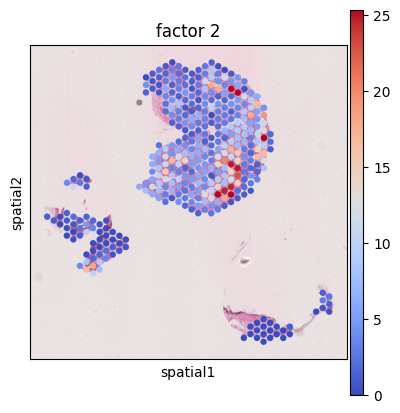

<Figure size 450x500 with 0 Axes>

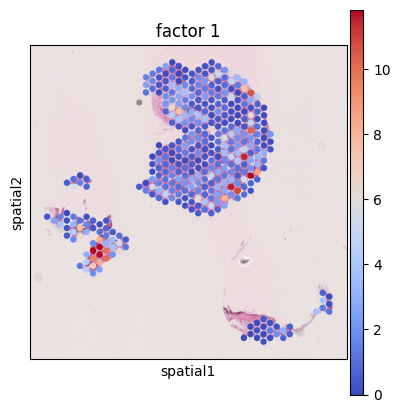

<Figure size 450x500 with 0 Axes>

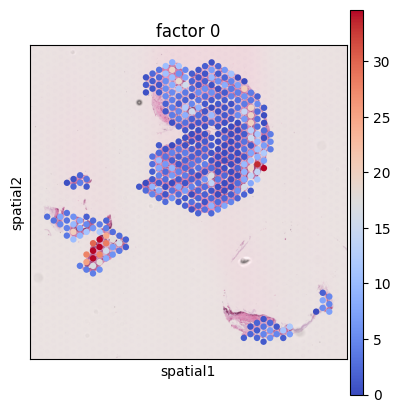

<Figure size 450x500 with 0 Axes>

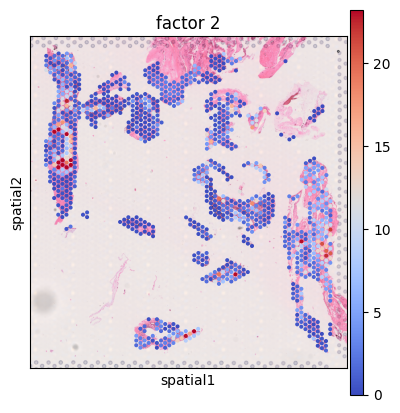

<Figure size 450x500 with 0 Axes>

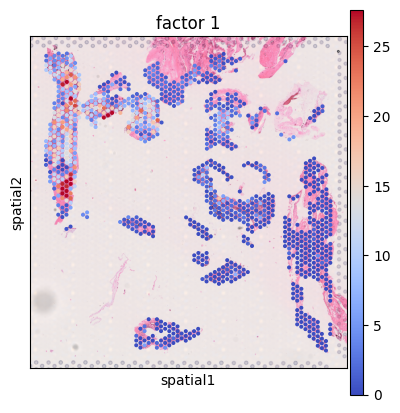

<Figure size 450x500 with 0 Axes>

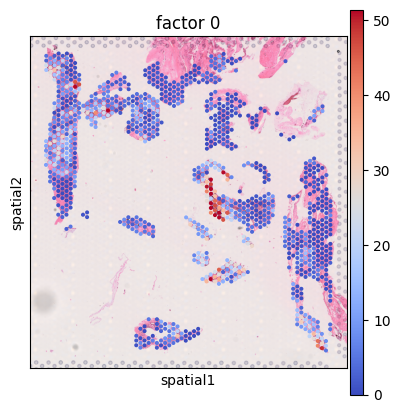

<Figure size 450x500 with 0 Axes>

In [26]:
# add 5% quantile, at least this much is present

%matplotlib inline
#mpl.use("Agg")

# Factor mapping for this model run
factor_titles = [
    'factor 2',
    'factor 1',
    'factor 0'
]

for sample in samples:
    slide = load_slide(sample, spatial_data_c2l_annot.obs)

    with mpl.rc_context({
        'axes.facecolor': 'black',
        'figure.figsize': [4.5, 5]
    }):

        for idx, fact in enumerate(model.location_factors_df.columns.tolist()):
                sc.pl.spatial(
                    slide, 
                    cmap='coolwarm',
                    color=fact,
                    size=1.3,
                    img_key='hires',
                    vmin=0,
                    vmax='p99',
                    title=factor_titles[idx]
                )
                plt.tight_layout()
                #plt.savefig(f'.../{sample}_NMF_n3_spatial_plot_factor_{factor_titles[idx][-1]}.pdf', bbox_inches="tight", dpi=300)
                #plt.savefig(f'.../{sample}_NMF_n3_spatial_plot_factor_{factor_titles[idx][-1]}.png', bbox_inches="tight", dpi=300)
                plt.show()

In [30]:
celltype_hierarchy = {
    "Endothelial cells": [
        'Unidentified EC',
        'Tip cells',
        'VenECs',
        'Immature ECs',
        'Stalk cells'
    ],
    "Stromal cells": [
        'Pericytes',
        'Myofibroblasts',
        'Unidentified stromal cluster',
        'EndMT cells',
        'Müller glia cells'
    ],
    "Myeloid cells": [
        'LYVE1+ BAMs',
        'Unidentified myeloid cluster 1',
        'MHCII+ BAMs',
        'Monocytes',
        'cDC2',
        'Unidentified myeloid cluster 5',
        'SAMs'
    ],
    "T cells": [
        'Exhausted CD8+ T cells',
        'CD4+ T cells',
        'γδ T cells',
        'Unidentified T cell cluster'
    ],
    "B cells": [
        "B cells"
    ],
    "Plasma cells": [
        "Plasma cells"
    ]
}

In [32]:
c2l_abundance_per_spot = spatial_data.obsm["q05_cell_abundance_w_sf"].copy()
c2l_abundance_per_spot.rename(columns=lambda x: x[23:], inplace=True)
# Divide by total abundance per spot
c2l_cell_type_proportion = c2l_abundance_per_spot.div(c2l_abundance_per_spot.sum(axis=1), axis=0)
# Rename columns to annotated names
annotated_pops = [] 
for pop in c2l_cell_type_proportion.columns:
    annotated_pops.append(subcell_to_title[pop])
print(annotated_pops)
c2l_cell_type_proportion.columns = annotated_pops
c2l_cell_type_proportion

['B cells', 'Unidentified EC', 'Tip cells', 'VenECs', 'Immature ECs', 'Stalk cells', 'LYVE1+ BAMs', 'Unidentified myeloid cluster 1', 'MHCII+ BAMs', 'Monocytes', 'cDC2', 'Unidentified myeloid cluster 5', 'SAMs', 'Plasma cells', 'Pericytes', 'Myofibroblasts', 'Unidentified stromal cluster', 'EndMT cells', 'Müller glia cells', 'Exhausted CD8+ T cells', 'CD4+ T cells', 'γδ T cells', 'Unidentified T cell cluster']


,B cells,Unidentified EC,Tip cells,VenECs,Immature ECs,Stalk cells,LYVE1+ BAMs,Unidentified myeloid cluster 1,MHCII+ BAMs,Monocytes,...,Plasma cells,Pericytes,Myofibroblasts,Unidentified stromal cluster,EndMT cells,Müller glia cells,Exhausted CD8+ T cells,CD4+ T cells,γδ T cells,Unidentified T cell cluster
human_eye_1_rerun_AAACAAGTATCTCCCA-1,0.031299,0.038323,0.047640,0.075599,0.017931,0.026297,0.023570,0.025916,0.032865,0.025179,...,0.012785,0.118477,0.219222,0.023723,0.009392,0.002237,0.034663,0.045513,0.029546,0.028194
human_eye_1_rerun_AAAGTGTGATTTATCT-1,0.031963,0.006569,0.110639,0.001931,0.022934,0.007254,0.031707,0.033671,0.018922,0.017748,...,0.002900,0.061361,0.273274,0.025186,0.023950,0.007421,0.083263,0.074842,0.026903,0.039979
human_eye_1_rerun_AAATACCTATAAGCAT-1,0.022342,0.029757,0.049811,0.115759,0.012452,0.033177,0.008405,0.007695,0.026583,0.007024,...,0.018883,0.115409,0.299986,0.013272,0.033466,0.002656,0.014408,0.018290,0.012274,0.030771
human_eye_1_rerun_AAATAGGGTGCTATTG-1,0.016454,0.001443,0.001339,0.001651,0.011867,0.003849,0.002955,0.006956,0.023003,0.010442,...,0.002184,0.000699,0.690039,0.019737,0.008473,0.028335,0.009040,0.011998,0.012717,0.031153
human_eye_1_rerun_AAATCTAGCCCTGCTA-1,0.033718,0.030532,0.053868,0.066390,0.016720,0.056287,0.033563,0.031108,0.018682,0.051549,...,0.006785,0.091385,0.176452,0.022636,0.007551,0.011457,0.054840,0.043015,0.021040,0.032906
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
human_eye_2_TTGTGGCCCTGACAGT-1,0.030370,0.003721,0.004618,0.015504,0.026615,0.007230,0.068926,0.106415,0.032021,0.035849,...,0.007252,0.071201,0.071329,0.034757,0.043247,0.012297,0.100707,0.072572,0.030385,0.030294
human_eye_2_TTGTGTATGCCACCAA-1,0.018370,0.033556,0.076004,0.075048,0.020571,0.095000,0.042188,0.019718,0.035527,0.009133,...,0.008298,0.311428,0.017869,0.019042,0.017004,0.003276,0.019844,0.017395,0.020747,0.018875
human_eye_2_TTGTGTTTCCCGAAAG-1,0.008420,0.040965,0.089148,0.080677,0.025534,0.024512,0.002403,0.003150,0.002603,0.003245,...,0.004750,0.306233,0.004270,0.020064,0.253698,0.000480,0.001796,0.003105,0.007922,0.011283
human_eye_2_TTGTTGGCAATGACTG-1,0.014077,0.006802,0.004421,0.046063,0.006668,0.016196,0.001857,0.004366,0.013872,0.004473,...,0.001053,0.005763,0.723075,0.011788,0.000630,0.003319,0.006813,0.008896,0.009458,0.026739


In [33]:
# Reorder B and plasma cells to the end of the column
c2l_cell_type_proportion = c2l_cell_type_proportion[
    [
 'Unidentified EC',
 'Tip cells',
 'VenECs',
 'Immature ECs',
 'Stalk cells',
 'Pericytes',
 'Myofibroblasts',
 'Unidentified stromal cluster',
 'EndMT cells',
 'Müller glia cells',
 'LYVE1+ BAMs',
 'Unidentified myeloid cluster 1',
 'MHCII+ BAMs',
 'Monocytes',
 'cDC2',
 'Unidentified myeloid cluster 5',
 'SAMs',
 'Exhausted CD8+ T cells',
 'CD4+ T cells',
 'γδ T cells',
 'Unidentified T cell cluster',
 'B cells',
 'Plasma cells']
 ]

c2l_cell_type_proportion

,Unidentified EC,Tip cells,VenECs,Immature ECs,Stalk cells,Pericytes,Myofibroblasts,Unidentified stromal cluster,EndMT cells,Müller glia cells,...,Monocytes,cDC2,Unidentified myeloid cluster 5,SAMs,Exhausted CD8+ T cells,CD4+ T cells,γδ T cells,Unidentified T cell cluster,B cells,Plasma cells
human_eye_1_rerun_AAACAAGTATCTCCCA-1,0.038323,0.047640,0.075599,0.017931,0.026297,0.118477,0.219222,0.023723,0.009392,0.002237,...,0.025179,0.034006,0.076444,0.021178,0.034663,0.045513,0.029546,0.028194,0.031299,0.012785
human_eye_1_rerun_AAAGTGTGATTTATCT-1,0.006569,0.110639,0.001931,0.022934,0.007254,0.061361,0.273274,0.025186,0.023950,0.007421,...,0.017748,0.030697,0.046323,0.020565,0.083263,0.074842,0.026903,0.039979,0.031963,0.002900
human_eye_1_rerun_AAATACCTATAAGCAT-1,0.029757,0.049811,0.115759,0.012452,0.033177,0.115409,0.299986,0.013272,0.033466,0.002656,...,0.007024,0.042275,0.077624,0.007679,0.014408,0.018290,0.012274,0.030771,0.022342,0.018883
human_eye_1_rerun_AAATAGGGTGCTATTG-1,0.001443,0.001339,0.001651,0.011867,0.003849,0.000699,0.690039,0.019737,0.008473,0.028335,...,0.010442,0.027011,0.064350,0.014305,0.009040,0.011998,0.012717,0.031153,0.016454,0.002184
human_eye_1_rerun_AAATCTAGCCCTGCTA-1,0.030532,0.053868,0.066390,0.016720,0.056287,0.091385,0.176452,0.022636,0.007551,0.011457,...,0.051549,0.054789,0.060246,0.024478,0.054840,0.043015,0.021040,0.032906,0.033718,0.006785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
human_eye_2_TTGTGGCCCTGACAGT-1,0.003721,0.004618,0.015504,0.026615,0.007230,0.071201,0.071329,0.034757,0.043247,0.012297,...,0.035849,0.005861,0.012447,0.176382,0.100707,0.072572,0.030385,0.030294,0.030370,0.007252
human_eye_2_TTGTGTATGCCACCAA-1,0.033556,0.076004,0.075048,0.020571,0.095000,0.311428,0.017869,0.019042,0.017004,0.003276,...,0.009133,0.010281,0.074062,0.036764,0.019844,0.017395,0.020747,0.018875,0.018370,0.008298
human_eye_2_TTGTGTTTCCCGAAAG-1,0.040965,0.089148,0.080677,0.025534,0.024512,0.306233,0.004270,0.020064,0.253698,0.000480,...,0.003245,0.009413,0.094902,0.001426,0.001796,0.003105,0.007922,0.011283,0.008420,0.004750
human_eye_2_TTGTTGGCAATGACTG-1,0.006802,0.004421,0.046063,0.006668,0.016196,0.005763,0.723075,0.011788,0.000630,0.003319,...,0.004473,0.017047,0.065484,0.001141,0.006813,0.008896,0.009458,0.026739,0.014077,0.001053


In [34]:
def viz_spatial_cell_props(
    spatial_data,
    c2l_cell_type_proportion,
    spatial_cluster,
    ylim=None,
    save=False, 
    color='tab:blue'):

    %matplotlib inline
    if save:
        mpl.use("Agg")

    cluster_spots = list(spatial_data[spatial_data.obs["cluster"] == spatial_cluster].obs.index)
    cell_props = c2l_cell_type_proportion.loc[cluster_spots]
    cell_props.loc["mean"] = cell_props.mean()
    wrapped_labels = [cellpop.replace(" ", '\n') for cellpop in cell_props.columns]

    fig, ax = plt.subplots(layout="constrained")
    ax.bar(x=cell_props.columns, height=cell_props.loc["mean"] * 100, color=color)
    ax.tick_params(rotation=90)
    ax.set_ylabel(f"Celltype proportions (%)")
    ax.set_xlabel("Celltypes")
    ax.set_title(f"Spatial cell proportions in {spatial_cluster} area")
    ax.yaxis.set_major_formatter('{x:.0f}')
    if ylim != None:
        ax.set_ylim(top=ylim)

    """if save:
        plt.savefig(f".../{spatial_cluster}_cell_proportions_{date}.pdf",bbox_inches="tight", dpi=300)
        plt.savefig(f".../{spatial_cluster}_cell_proportions_{date}.png",bbox_inches="tight", dpi=300)"""
    plt.show()

### Supplementary figure 5

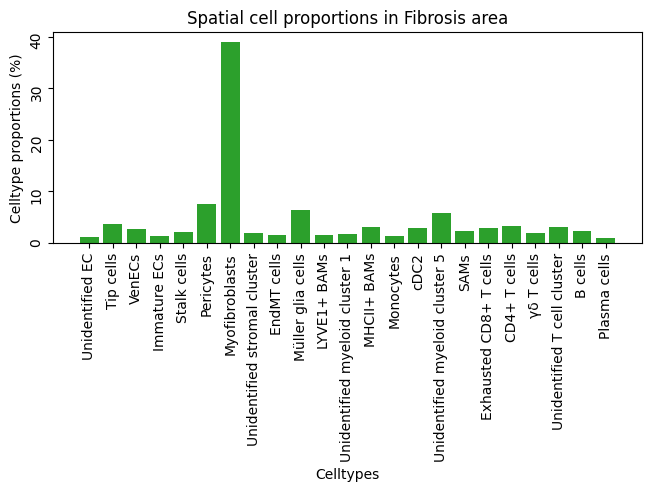

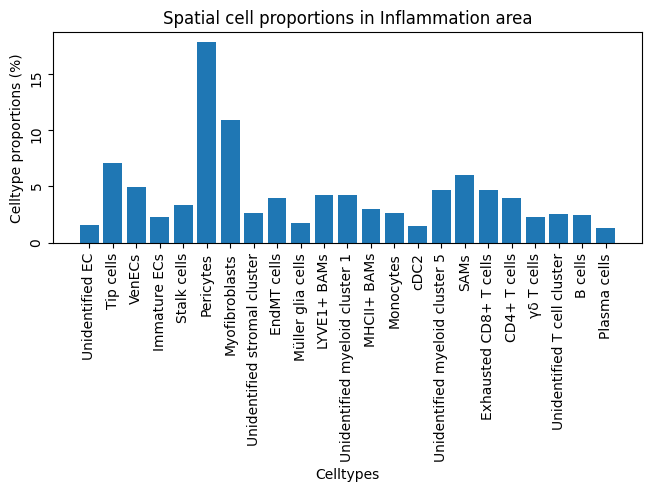

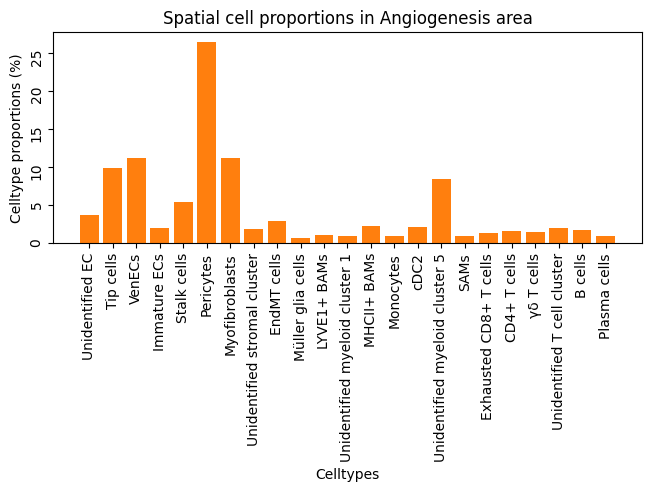

In [35]:
# tab:blue, tab:orange, tab:green are the basic tableau colors present in spatial plots
viz_spatial_cell_props(
    spatial_data,
    c2l_cell_type_proportion,
    "Fibrosis",
    save=False,
    color='tab:green'
)

viz_spatial_cell_props(
    spatial_data,
    c2l_cell_type_proportion,
    "Inflammation",
    save=False
)

viz_spatial_cell_props(
    spatial_data,
    c2l_cell_type_proportion,
    "Angiogenesis",
    save=False,
    color='tab:orange'
)

In [36]:
for key in celltype_hierarchy:
    c2l_cell_type_proportion[f"{key}"] = c2l_cell_type_proportion[celltype_hierarchy[key]].sum(axis=1)

c2l_cell_type_proportion

,Unidentified EC,Tip cells,VenECs,Immature ECs,Stalk cells,Pericytes,Myofibroblasts,Unidentified stromal cluster,EndMT cells,Müller glia cells,...,Exhausted CD8+ T cells,CD4+ T cells,γδ T cells,Unidentified T cell cluster,B cells,Plasma cells,Endothelial cells,Stromal cells,Myeloid cells,T cells
human_eye_1_rerun_AAACAAGTATCTCCCA-1,0.038323,0.047640,0.075599,0.017931,0.026297,0.118477,0.219222,0.023723,0.009392,0.002237,...,0.034663,0.045513,0.029546,0.028194,0.031299,0.012785,0.205790,0.373052,0.239158,0.137916
human_eye_1_rerun_AAAGTGTGATTTATCT-1,0.006569,0.110639,0.001931,0.022934,0.007254,0.061361,0.273274,0.025186,0.023950,0.007421,...,0.083263,0.074842,0.026903,0.039979,0.031963,0.002900,0.149327,0.391192,0.199632,0.224986
human_eye_1_rerun_AAATACCTATAAGCAT-1,0.029757,0.049811,0.115759,0.012452,0.033177,0.115409,0.299986,0.013272,0.033466,0.002656,...,0.014408,0.018290,0.012274,0.030771,0.022342,0.018883,0.240956,0.464790,0.177285,0.075744
human_eye_1_rerun_AAATAGGGTGCTATTG-1,0.001443,0.001339,0.001651,0.011867,0.003849,0.000699,0.690039,0.019737,0.008473,0.028335,...,0.009040,0.011998,0.012717,0.031153,0.016454,0.002184,0.020149,0.747282,0.149023,0.064908
human_eye_1_rerun_AAATCTAGCCCTGCTA-1,0.030532,0.053868,0.066390,0.016720,0.056287,0.091385,0.176452,0.022636,0.007551,0.011457,...,0.054840,0.043015,0.021040,0.032906,0.033718,0.006785,0.223798,0.309481,0.274416,0.151802
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
human_eye_2_TTGTGGCCCTGACAGT-1,0.003721,0.004618,0.015504,0.026615,0.007230,0.071201,0.071329,0.034757,0.043247,0.012297,...,0.100707,0.072572,0.030385,0.030294,0.030370,0.007252,0.057687,0.232830,0.437902,0.233959
human_eye_2_TTGTGTATGCCACCAA-1,0.033556,0.076004,0.075048,0.020571,0.095000,0.311428,0.017869,0.019042,0.017004,0.003276,...,0.019844,0.017395,0.020747,0.018875,0.018370,0.008298,0.300181,0.368618,0.227673,0.076861
human_eye_2_TTGTGTTTCCCGAAAG-1,0.040965,0.089148,0.080677,0.025534,0.024512,0.306233,0.004270,0.020064,0.253698,0.000480,...,0.001796,0.003105,0.007922,0.011283,0.008420,0.004750,0.260836,0.584745,0.117143,0.024106
human_eye_2_TTGTTGGCAATGACTG-1,0.006802,0.004421,0.046063,0.006668,0.016196,0.005763,0.723075,0.011788,0.000630,0.003319,...,0.006813,0.008896,0.009458,0.026739,0.014077,0.001053,0.080150,0.744574,0.108239,0.051906


In [51]:
c2l_cell_type_proportion_for_df = c2l_cell_type_proportion[
    [
        'Endothelial cells',
        'Unidentified EC',
        'Tip cells',
        'VenECs',
        'Immature ECs',
        'Stalk cells',
        'Stromal cells',
        'Pericytes',
        'Myofibroblasts',
        'Unidentified stromal cluster',
        'EndMT cells',
        'Müller glia cells',
        'Myeloid cells',
        'LYVE1+ BAMs',
        'Unidentified myeloid cluster 1',
        'MHCII+ BAMs',
        'Monocytes',
        'cDC2',
        'Unidentified myeloid cluster 5',
        'SAMs',
        'T cells',
        'Exhausted CD8+ T cells',
        'CD4+ T cells',
        'γδ T cells',
        'Unidentified T cell cluster',
        'B cells',
        'Plasma cells'
    ]
].copy()

c2l_cell_type_proportion_for_df.mean()

Endothelial cells                 0.191295
Unidentified EC                   0.019341
Tip cells                         0.064458
VenECs                            0.055509
Immature ECs                      0.018168
Stalk cells                       0.033819
Stromal cells                     0.461349
Pericytes                         0.159533
Myofibroblasts                    0.220655
Unidentified stromal cluster      0.021025
EndMT cells                       0.027013
Müller glia cells                 0.033123
Myeloid cells                     0.207406
LYVE1+ BAMs                       0.023867
Unidentified myeloid cluster 1    0.024226
MHCII+ BAMs                       0.028159
Monocytes                         0.016516
cDC2                              0.021688
Unidentified myeloid cluster 5    0.060422
SAMs                              0.032527
T cells                           0.107214
Exhausted CD8+ T cells            0.031365
CD4+ T cells                      0.030999
γδ T cells 

In [52]:
spatial_areas = ['Inflammation', 'Angiogenesis', 'Fibrosis']

means_dict = {}

for sp_area in spatial_areas:
    cluster_spots = list(spatial_data[spatial_data.obs["cluster"] == sp_area].obs.index)
    cell_props = c2l_cell_type_proportion_for_df.loc[cluster_spots]
    means_dict[sp_area] = cell_props.mean()

### Base for supplementary table 6

In [54]:
df = pd.DataFrame(data=means_dict)
df = df * 100
df.head()
# Rest of the table construction is easier to do in e.g., excel
#df.to_excel(excel_writer=f".../spatial_area_cell_proportions_{date}.xlsx")

,Inflammation,Angiogenesis,Fibrosis
Endothelial cells,19.329167,32.017414,10.789032
Unidentified EC,1.617287,3.707039,1.096525
Tip cells,7.085231,9.881893,3.694703
VenECs,4.954334,11.103635,2.571470
Immature ECs,2.313466,1.952226,1.284287
